# MLFactor long-only research analysis

Research draft. This notebook presents saved evidence through the shared research library. It does not train models during report builds. A four-recipe training feature study is included. Final tuning integration and the submission choice remain pending.

## Load the deliberately selected experiment

The release file pins a run ID. This prevents a later app experiment from silently changing the report.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))
from IPython.display import display
from research.reporting import load_release, predictive_table, portfolio_table, portfolio_figure, readiness, benchmark_table
import matplotlib.pyplot as plt
import pandas as pd
summary = load_release()
print("Pinned run:", summary["run_id"])

Pinned run: 20261108T144257_f45441ba8e83


## Explicit experiment configuration

The following cell exposes the reusable computation entry point. Leave `REBUILD_EXPERIMENT=False` when reading or rendering the notebook. Set it deliberately in an interactive research session to regenerate an experiment. Saved results are pinned separately before report generation. Builds enforce artifact-only execution.

In [2]:
from research import RunConfig, FeatureSpec, default_model_registry, default_registry
from research.store import ExperimentStore

experiment_config = RunConfig(
    strategies=tuple(default_registry()),
    include_ml=True,
    models=tuple(default_model_registry()),
    feature_spec=FeatureSpec(),
    fit_policy="expanding",  # Use frozen_at_origin for official test model fits.
)
REBUILD_EXPERIMENT = False
if REBUILD_EXPERIMENT:
    computed = ExperimentStore().get_or_run(experiment_config, force=True)
    print("Saved experiment:", computed.cache_info["run_id"])
else:
    print("Reading pinned evidence; no models are fitted.")

Reading pinned evidence; no models are fitted.


## Data and timing

A source row at month-end t contains the simple return earned in t+1. Model inputs exclude IDs and forward labels. Historical training joins labels only after they become known. The model-validation window is separate from the full-window equal-weight reference.

In [3]:
display(pd.DataFrame([{"Property": key, "Value": str(value)} for key, value in summary["data_audit"].items() if key not in {"source_features", "fitted_screens"}]))

,Property,Value
0,source_splits,['train']
1,training_source_rows,140739
2,training_source_stocks,1204
3,input_rows,140739
4,evaluation_rows,71631
5,evaluation_stocks,1197
6,evaluation_months,60
7,first_snapshot,2004-12-31
8,last_snapshot,2009-11-30
9,first_return_month,2005-01-31


## Independent equal-weight accounting check

Average stock simple returns within a month, then compound portfolio returns across months. Do not average stock log returns to construct equal-capital portfolio returns.

In [4]:
display(benchmark_table().style.format({"Months":"{:.0f}","CAGR":"{:.2%}","Volatility":"{:.2%}","Sharpe":"{:.3f}","Max drawdown":"{:.2%}"}))

,Period,Months,CAGR,Volatility,Sharpe,Max drawdown
0,train,120,14.50%,19.92%,0.783,-49.51%
1,test,108,13.10%,15.63%,0.868,-20.64%


## Same trading rules, different fixed classifiers

All selected models use the same declared factor recipe, date schedule and loss-probability adjustment. The original portfolio appears once per strategy. Lower Brier score and log loss are better; classification and portfolio performance are separate evaluations.

In [5]:
display(predictive_table(summary).style.format({"Brier score":"{:.6f}","Log loss":"{:.6f}","ROC AUC":"{:.4f}"}))
display(portfolio_table(summary).style.format("{:.2%}"))

,Predictor,Brier score,Log loss,ROC AUC
0,Logistic regression,0.249667,0.692578,0.5008
1,Historical loss-rate control,0.249023,0.691215,0.4948
2,Gaussian naive Bayes,0.259759,0.714980,0.5094
3,Random forest,0.249387,0.692021,0.5058
4,Histogram gradient boosting,0.249715,0.692719,0.5073


Strategy,Equal weight,Frozen high-vol + momentum,Momentum
Version,,,
Original,7.62%,2.64%,-1.74%
Logistic regression,7.57%,2.79%,-1.74%
Gaussian naive Bayes,7.51%,3.38%,-1.53%
Random forest,7.59%,2.68%,-1.69%
Histogram gradient boosting,7.58%,2.56%,-1.70%


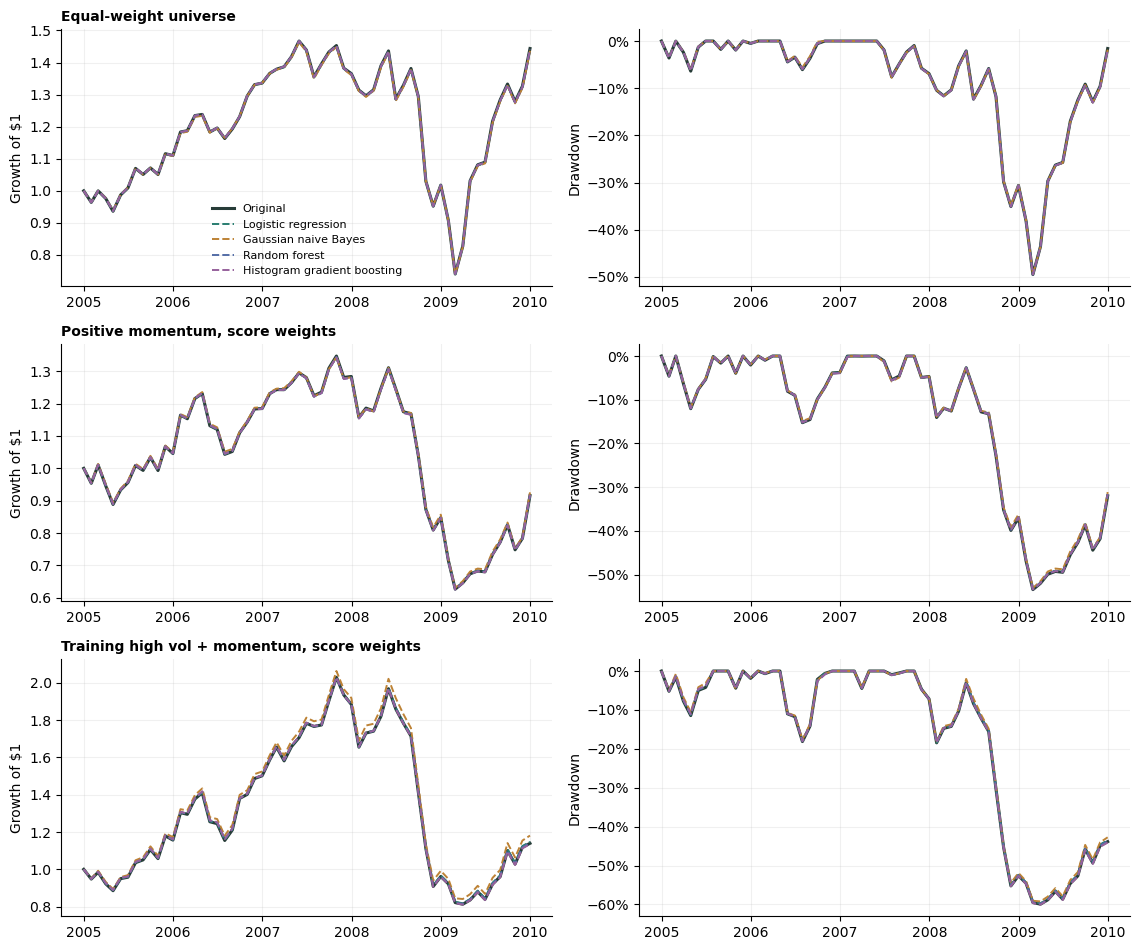

In [6]:
figure = portfolio_figure(summary)
display(figure)
plt.close(figure)

## Feature selection: a separately pinned matched study

The release pins the completed four-recipe study independently of the older main
experiment. Its fourteen strategies use pooled downside predictions, annual
training-only selection/refitting, adjustment strength 0.50, and three-month
momentum for the cash-capable annual-consistency rule. Earned validation months
are January 2005–December 2009. Loading this evidence does not refit anything.

In [7]:
from IPython.display import Markdown
from research.feature_reporting import (
    method_notes, importance_table, importance_figure, selection_overlap,
    prediction_summary, portfolio_table as feature_portfolio_table,
    portfolio_figure as feature_portfolio_figure, forest_findings,
)
feature_study = summary.get("feature_study")
if feature_study is not None:
    print("Pinned feature study:", feature_study["metadata"]["study_id"])
    display(Markdown(method_notes()))
    display(pd.DataFrame([{"Recipe": key, "Saved run": value}
                         for key, value in feature_study["metadata"]["runs"].items()]))
else:
    print("No feature study is pinned in this release.")

Pinned feature study: features_20261109T202318_8b01fe74


**All 20 factors** is the exploratory reference. Each learned recipe selects
at most ten inputs using only outcomes available at that historical training
date, then independently retrains each classifier. Preprocessing and selection
remain inside the model pipeline, including inside future tuning folds.

- **ANOVA top 10:** rank factors individually by training separation between
  loss and non-loss outcomes; retain the highest-ranked varying inputs.
- **Correlation-pruned up to 10:** follow the ANOVA ranking while rejecting
  factors too correlated with a higher-ranked retained input. Use the saved
  correlation threshold; do not backfill rejected duplicates.
- **Random forest top 10:** fit a separate selector forest on all candidate
  inputs and rank their mean decrease in impurity. Retain the highest-ranked
  varying inputs, then fit the chosen prediction model. A forest selector can
  supply inputs to logistic regression, naive Bayes, boosting or another forest.

**Reading the forest chart:** longer bars indicate more training split
importance. Highlighted bars are the selected inputs. Error bars show standard
deviation across trees, not confidence intervals or future-return uncertainty.
Importance does not give the direction of an effect or establish causality.
Correlated factors can share importance, and inputs with more possible split
points can receive inflated importance. ANOVA scores and forest importances have
different units; compare selected names and later outcomes across methods.

**Reading the comparisons:** lower Brier score and log loss are better. Compare
each selected recipe with the same predictor using all twenty factors and with
the historical event-frequency control. Then compare the resulting portfolios
over identical months. Feature selection changes ML inputs; non-ML rules remain
unchanged references. A favorable return does not establish useful prediction.
Annual masks may differ; their union is not a fixed final ten-factor model.

Method references: textbook chapter 29 introduces tree importance and random
forests; [sklearn's forest example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html)
illustrates importance and tree variability. See its
[permutation-importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html)
for further interpretation limits. Permutation selection is not part of this study.


,Recipe,Saved run
0,all_20,20261109T202421_184e95372ab2
1,anova_10,20261109T202516_039a5a86258b
2,pruned_10,20261109T202612_7da383c77e5b
3,forest_10,20261109T202931_597510736fb4


### Actual selected inputs and forest importance

The forest selector ranks all twenty supplied factors using then-known outcomes.
Highlighted bars show selected factors; error bars are standard deviation across
trees. They are not confidence intervals. The plot below shows the first fit;
change the snapshot argument to inspect another recorded historical origin.

,feature,group,meaning,rank,score,importance_std
0,Div_Yld,Valuation / payout,Dividend yield,1,0.103349,0.068836
1,Ocf_Ce,Cash flow,Operating cash flow / capital employed,2,0.087515,0.052694
2,Fcf_Yld,Valuation / payout,Free cash flow yield,3,0.086404,0.045150
3,Tev_Less_Mktcap,Debt,Total enterprise value minus market capitaliza...,4,0.081036,0.048784
4,Share_Turn_3M,Trading activity,Average share turnover over 3 months,5,0.072464,0.061928
5,Ev_Ebitda,Valuation / payout,Enterprise value / EBITDA,6,0.070386,0.046254
6,Share_Turn_6M,Trading activity,Average share turnover over 6 months,7,0.062124,0.060915
7,Capex_Sales,Investment,Capital expenditure / sales,8,0.060420,0.041817
8,Share_Turn_12M,Trading activity,Average share turnover over 12 months,9,0.056824,0.061115
9,Tot_Debt_Rev,Debt,Total debt / revenue,10,0.046166,0.039074


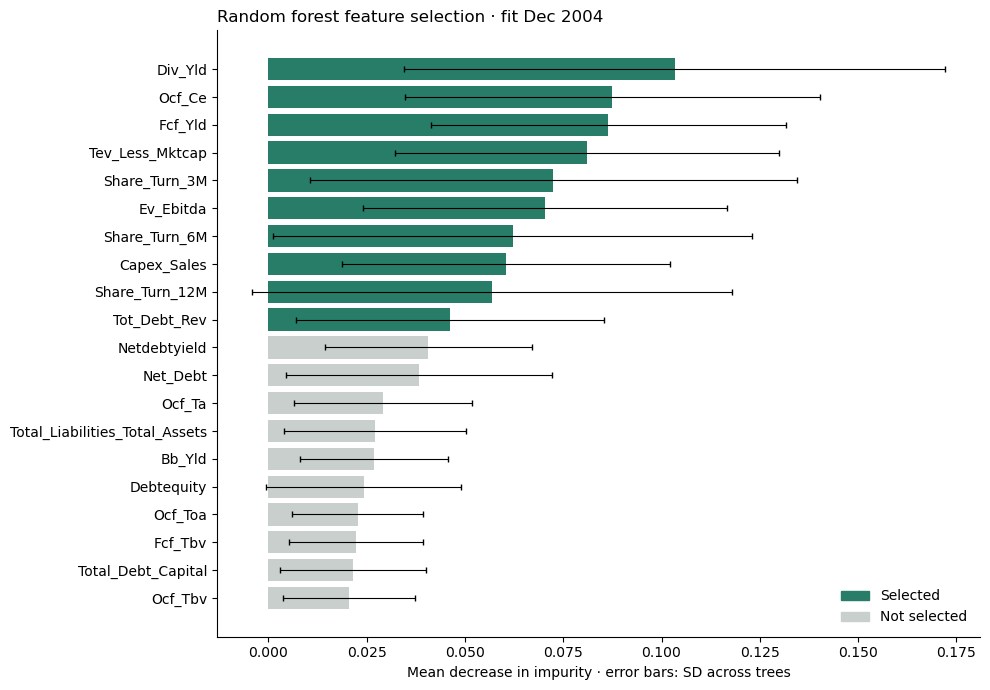

,ANOVA top 10,Correlation-pruned up to 10 (|r| < 0.90),Random forest top 10
ANOVA top 10,10,7,8
Correlation-pruned up to 10 (|r| < 0.90),7,10,6
Random forest top 10,8,6,10


In [8]:
if feature_study is not None:
    chosen = importance_table(feature_study)
    display(chosen.loc[chosen.selected, ["feature", "group", "meaning", "rank", "score", "importance_std"]])
    figure = importance_figure(feature_study)
    display(figure)
    plt.close(figure)
    display(selection_overlap(feature_study))

### Compare independently retrained models

Every predictor has a separately fitted model per recipe/origin. Compare Brier
score and log loss with that predictor's all-twenty version and the common
historical loss-frequency control. Non-ML portfolio rules are unchanged.

In [9]:
if feature_study is not None:
    display(Markdown(forest_findings(feature_study)))
    display(prediction_summary(feature_study)[[
        "model_id", "recipe", "brier_score", "log_loss", "roc_auc",
        "Brier change vs all 20", "Log-loss change vs all 20",
    ]].round(6))

Forest selection lowers Brier score relative to all twenty factors for 2 of 4 predictors. 0 of the forest-selected predictors beat the historical event-frequency control on Brier score (control: 0.249023). These are training-validation comparisons; portfolio effects must be assessed separately. They do not declare a final feature/model choice or provide a tuned frozen-test result.

,model_id,recipe,brier_score,log_loss,roc_auc,Brier change vs all 20,Log-loss change vs all 20
0,logistic,all_20,0.249667,0.692578,0.500801,0.000000,0.000000
1,logistic,anova_10,0.249434,0.692080,0.502109,-0.000233,-0.000498
2,logistic,pruned_10,0.249507,0.692236,0.502248,-0.000160,-0.000342
3,logistic,forest_10,0.249474,0.692174,0.503437,-0.000192,-0.000404
4,naive_bayes,all_20,0.259759,0.714980,0.509354,0.000000,0.000000
5,naive_bayes,anova_10,0.257497,0.709745,0.508686,-0.002262,-0.005235
6,naive_bayes,pruned_10,0.254021,0.701998,0.506972,-0.005738,-0.012982
7,naive_bayes,forest_10,0.254489,0.702917,0.509923,-0.005270,-0.012064
8,random_forest,all_20,0.249387,0.692021,0.505785,0.000000,0.000000
9,random_forest,anova_10,0.249428,0.692101,0.508019,0.000041,0.000080


### Portfolio example: logistic overlay on momentum with cash

Keep the predictor, trading rule, dates and allocation settings fixed. Compare
four feature recipes and show the unchanged non-ML reference once. CAGR and
annual log growth describe the same compounded portfolio using different scales.
Results are gross of costs; cash earns an assumed zero monthly return.

,recipe,cagr,annualized_log_growth,sharpe,sortino,max_drawdown,avg_one_way_turnover,avg_cash_weight,change_cagr_vs_all20
52,all_20,0.035099,0.034497,0.434859,0.704686,-0.175582,0.207378,0.563740,0.000000
108,anova_10,0.035230,0.034624,0.435831,0.706767,-0.175590,0.207478,0.563433,0.000131
164,pruned_10,0.035144,0.034541,0.435164,0.705400,-0.175636,0.207440,0.563566,0.000046
220,forest_10,0.035219,0.034613,0.435711,0.706545,-0.175615,0.207546,0.563278,0.000120


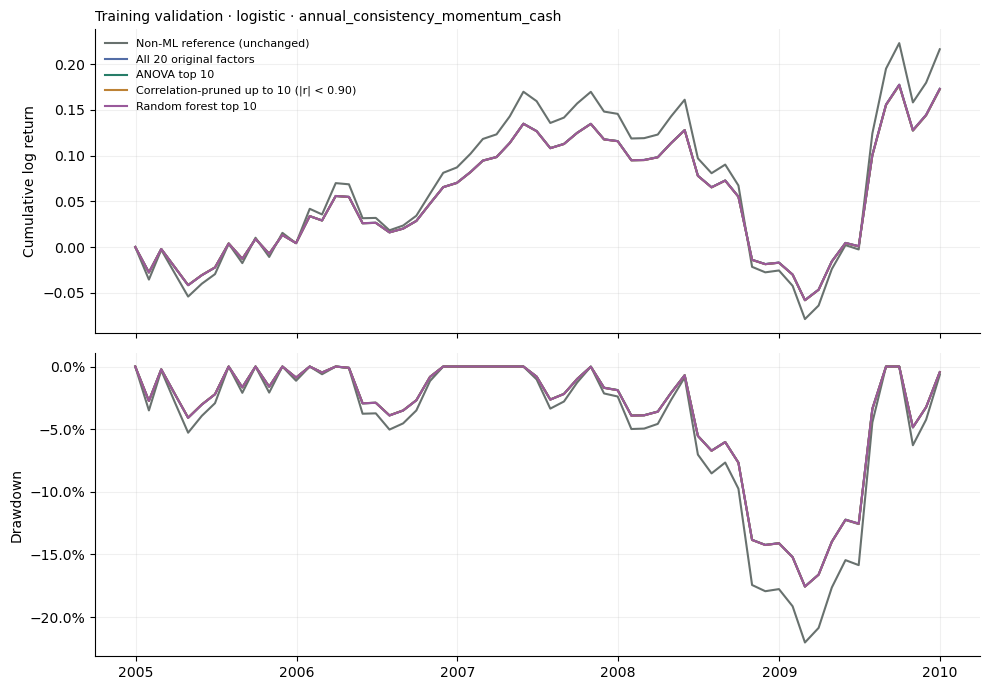

In [10]:
if feature_study is not None:
    display(feature_portfolio_table(feature_study, "logistic", ["annual_consistency_momentum_cash"])[[
        "recipe", "cagr", "annualized_log_growth", "sharpe", "sortino", "max_drawdown",
        "avg_one_way_turnover", "avg_cash_weight", "change_cagr_vs_all20",
    ]].round(6))
    figure = feature_portfolio_figure(feature_study, cumulative_log=True)
    display(figure)
    plt.close(figure)

## Separate tuning evidence and pending final evaluation

The fixed training study does not choose a final ten-feature specification.
Annual masks may change and their union is not a final model. The next research
steps are a justified feature choice, integration of the separate training-
holdout tuning evidence, and a frozen-training final test evaluation. The app
has a saved logistic/boosting tuning comparison over 2007–2009, outside this
fixed-model feature study. No forest-selected tuned comparison or official final
test result is claimed here.

## Reproduction commands

Computation is explicit and saves its results before presentation:

```bash
python3 -m research --all --all-models
python3 -m research --saved
python3 build_submission.py --pin-run RUN_ID
```

For official test model fits, choose `--evaluation test --fit-policy frozen_at_origin`. That fits models using only outcomes known before evaluation begins. The test period has already been viewed and is not a fresh holdout.

## Remaining evidence before the final hand-in

In [11]:
display(pd.DataFrame([{"Requirement":key,"Recorded":value} for key,value in readiness(summary).items()]))

,Requirement,Recorded
0,Declared input subset has at most 10 features,False
1,Four model types recorded,True
2,GridSearchCV evidence for at least two models,False
3,Two non-ML controls including equal weight,True
4,Risk and reward metrics recorded,True
5,Official test models frozen before evaluation,False
6,Final strategy/model choice recorded,False
